# Cartera dedicada · Criptomonedas

**Objetivo.** Aislar la clase con mayor volatilidad y con un calendario distinto al de los activos
tradicionales.

- **Universo:** cuatro pares de Kraken: `BTC/USD`, `ETH/USD`, `SOL/USD` y `ADA/USD`, con el mismo peso.
- **Moneda:** USD. La biblioteca no convierte divisas, así que todos los ejemplos usan una sola moneda.
- **Ventana:** desde `2025-01-02` hasta la última vela disponible.
- **Anualización:** 365 días, porque el mercado cotiza todos los días.

Kraken solo conserva las últimas 720 velas diarias (≈2 años). La fecha de inicio elegida está dentro
de esa ventana; si deja de estarlo, `KrakenSource` lanza un error explicativo en lugar de devolver una
serie truncada. La cartera usa el proveedor directo, sin caché CSV, para no crear rutas anidadas con
la barra de `BTC/USD`.

In [1]:
"""Cartera dedicada de criptomonedas: ingesta, informe y simulación."""

from IPython.display import Markdown

from quantfolio import KrakenSource, MonteCarloParameters, Portfolio

START = "2025-01-02"
TICKERS = ["BTC/USD", "ETH/USD", "SOL/USD", "ADA/USD"]
WEIGHTS = {"BTC/USD": 0.25, "ETH/USD": 0.25, "SOL/USD": 0.25, "ADA/USD": 0.25}
PERIODS_PER_YEAR = 365

## 1 · Ingesta

Kraken expone una API pública OHLC sin clave. `get_many()` descarga los cuatro pares y los normaliza
en `PriceSeries`. El calendario es de siete días: no hay cierre de fin de semana, así que la cartera
tiene 365 observaciones potenciales al año. Kraken solo conserva las últimas 720 velas diarias
(≈2 años); si `START` queda fuera de esa ventana, la fuente lanza un error explicativo en lugar de
devolver una serie truncada.

In [2]:
source = KrakenSource()
assets = source.get_many(TICKERS, start=START)

for ticker, asset in assets.items():
    print(
        f"{ticker:>8} | {asset.source:<10} | "
        f"{asset.prices.index.min().date()} → {asset.prices.index.max().date()} | "
        f"{len(asset.prices)} observaciones"
    )

 BTC/USD | Kraken     | 2025-01-02 → 2026-11-06 | 674 observaciones
 ETH/USD | Kraken     | 2025-01-02 → 2026-11-06 | 674 observaciones
 SOL/USD | Kraken     | 2025-01-02 → 2026-11-06 | 674 observaciones
 ADA/USD | Kraken     | 2025-01-02 → 2026-11-06 | 674 observaciones


## 2 · Cartera

`Portfolio` valida que haya un peso por activo, normaliza los pesos y alinea los calendarios por
intersección. La cobertura indica qué fechas conserva el análisis después de esa alineación.

In [3]:
portfolio = Portfolio(assets=assets, weights=WEIGHTS)

print("Pesos normalizados:")
for ticker, weight in portfolio.weights.items():
    print(f"  {ticker}: {weight:.2%}")

print("\nDiagnóstico de alineación temporal:", portfolio.alignment_summary())

Pesos normalizados:
  BTC/USD: 25.00%
  ETH/USD: 25.00%
  SOL/USD: 25.00%
  ADA/USD: 25.00%

Diagnóstico de alineación temporal: {'union_dates': 674, 'common_dates': 674, 'coverage': 1.0}


## 3 · Informe

El informe Markdown reúne la composición, las métricas anualizadas, la calidad de los datos y las
advertencias de riesgo. Las advertencias se calculan a partir del estado real de la cartera.

In [4]:
Markdown(portfolio.report(periods_per_year=PERIODS_PER_YEAR))

# Informe de la cartera

## 1. Composición

| Activo | Peso |
|---|---:|
| BTC/USD | 25.00% |
| ETH/USD | 25.00% |
| SOL/USD | 25.00% |
| ADA/USD | 25.00% |

## 2. Métricas históricas

| Métrica | Valor |
|---|---:|
| Rentabilidad media diaria | -0.0460% |
| Volatilidad diaria | 3.4282% |
| Rentabilidad anualizada aproximada | -16.80% |
| Volatilidad anualizada | 65.50% |

## 3. Calidad de los datos

- Activos: 4
- Fechas en la unión de calendarios: 674
- Fechas comunes a todos los activos: 674
- Cobertura tras la alineación: 100.0%
- Observaciones de rentabilidad: 673

## 4. Advertencias de riesgo

- Las rentabilidades históricas no garantizan resultados futuros.
- La simulación de Monte Carlo depende de los supuestos de rentabilidad y volatilidad.

## 4 · Panel analítico

El primer panel muestra la evolución de precios **reajustada a base 100**, para que activos con
precios nominales distintos se puedan comparar. Los otros tres paneles muestran la rentabilidad
acumulada, la matriz de correlación y el valor de la cartera.

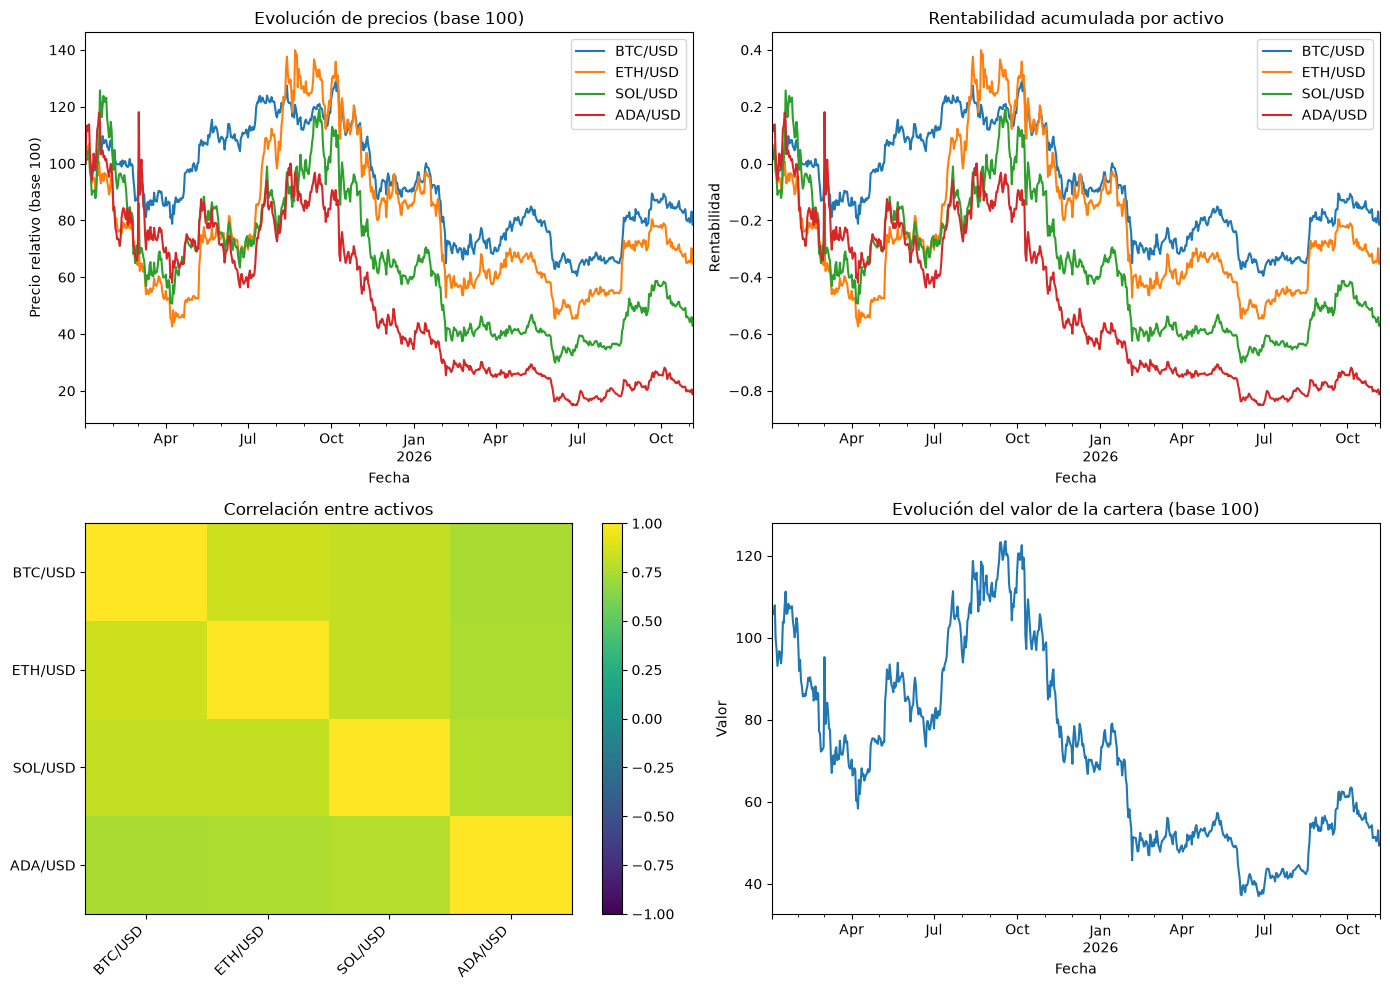

In [5]:
portfolio.plots_report()

## 5 · Simulación Monte Carlo

La simulación usa la deriva y la volatilidad logarítmicas estimadas de la historia. El horizonte
se expresa en los mismos periodos que la anualización de la cartera, de modo que el número de
pasos y los supuestos compartan el mismo calendario. La distribución final permite leer el abanico
de resultados, no una predicción puntual.

count      2000.00
mean       8392.72
std        6565.85
min         854.13
5%         2319.11
50%        6971.29
95%       19911.16
max      131785.75
Name: 365, dtype: float64


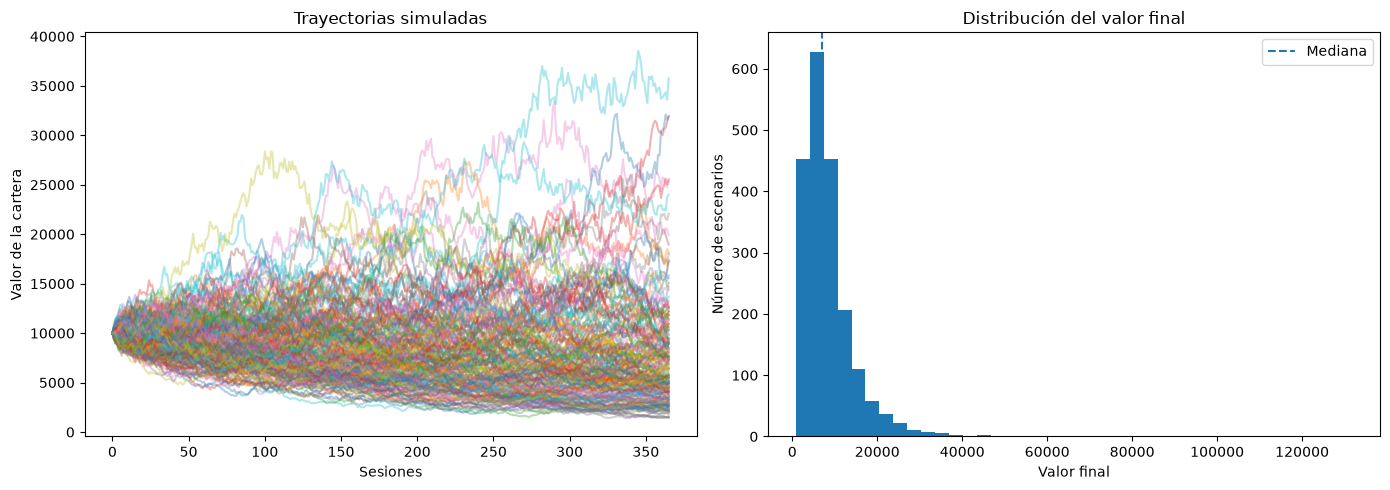

In [6]:
simulations = portfolio.simulate_monte_carlo(
    MonteCarloParameters(
        n_paths=2_000,
        horizon=PERIODS_PER_YEAR,
        periods_per_year=PERIODS_PER_YEAR,
        seed=42,
    )
)

final_values = simulations.iloc[-1]
print(final_values.describe(percentiles=[0.05, 0.5, 0.95]).round(2))
portfolio.plot_simulation(simulations, max_paths=200)

## 6 · Qué aporta esta clase

La cripto es la clase con mayor volatilidad de la cartera y la única que cotiza todos los días. Por
eso se anualiza con 365 periodos, no con 252. Su correlación con la renta variable y la renta fija es
inestable, lo que la convierte en un satélite pequeño más que en un núcleo: aporta diversificación
potencial, pero también colas gruesas y riesgo de liquidez. Al mezclarla con activos de lunes a
viernes, la alineación por intersección descarta sus observaciones de fin de semana.